In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt



In [3]:
df = pd.read_csv('C:\\Users\\amanm\\OneDrive\\Desktop\\dont open\\Career\\Breakthrough Team\\Personal\\data\\EmanuelMessele_fraud_oracle_cleaned.csv')

In [4]:
# --- Features / target: only the columns with proven signal ---
keep_cols = ['Fault', 'BasePolicy', 'PolicyType', 'VehicleCategory', 'AgentType',
             'AccidentArea', 'PastNumberOfClaims', 'AgeOfPolicyHolder',
             'WitnessPresent', 'PoliceReportFiled']

X = df[keep_cols]
y = df['FraudFound_P']

In [5]:
# one hot encode
X = pd.get_dummies(X, drop_first=True)

In [6]:
# --- Train / Validation / Test split (70/15/15, stratified) ---
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, stratify=y_temp, random_state=42
)
# temp variables just hold intermediate splits before final train/validation/test split
# stratify - ensures that the proportion of classes in the target variable 'y' is maintained in the train, validation, and test sets.

In [7]:
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Train fraud rate:", y_train.mean().round(4))
print("Val fraud rate:  ", y_val.mean().round(4))
print("Test fraud rate: ", y_test.mean().round(4))

Train: (10799, 28) | Val: (2307, 28) | Test: (2313, 28)
Train fraud rate: 0.0599
Val fraud rate:   0.0598
Test fraud rate:  0.0597


In [8]:
# --- Model: Logistic Regression with class weighting for imbalance ---
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [9]:
# --- Evaluate on validation set only (test stays untouched) ---
y_val_pred = model.predict(X_val)

print("\n=== Validation Performance ===")
print(classification_report(y_val, y_val_pred))
print(confusion_matrix(y_val, y_val_pred))


=== Validation Performance ===
              precision    recall  f1-score   support

           0       0.99      0.58      0.73      2169
           1       0.12      0.93      0.22       138

    accuracy                           0.60      2307
   macro avg       0.56      0.76      0.47      2307
weighted avg       0.94      0.60      0.70      2307

[[1255  914]
 [   9  129]]


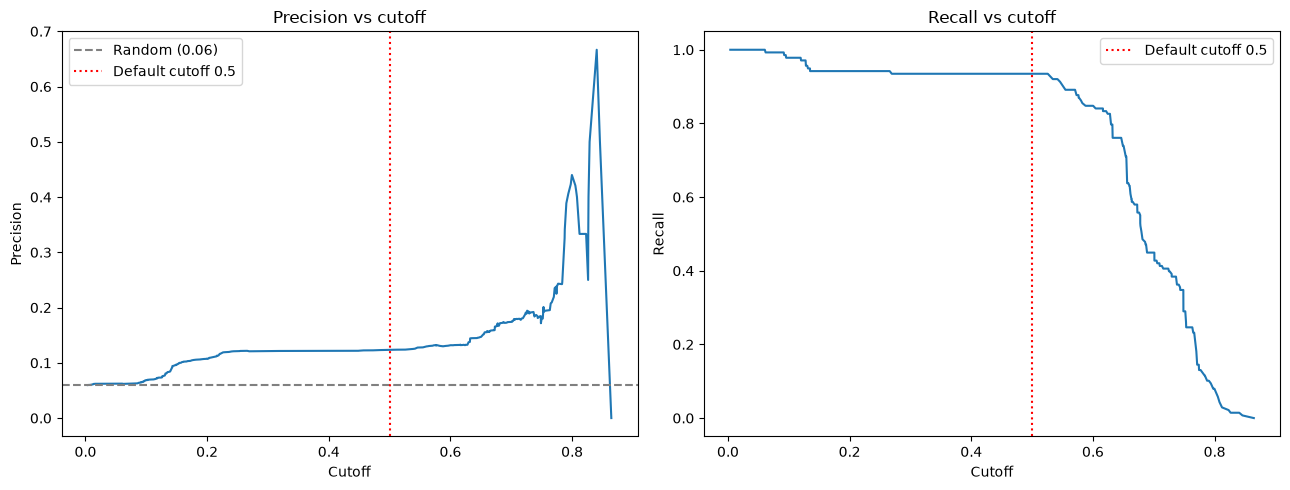

In [21]:
p = model.predict_proba(X_val)[:, 1]
prec, rec, thresholds = precision_recall_curve(y_val, p)
# prec and rec each have one extra trailing point with no cutoff, so drop it to match thresholds
prec, rec = prec[:-1], rec[:-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(thresholds, prec)
axes[0].axhline(y_val.mean(), color='gray', linestyle='--', label=f'Random ({y_val.mean():.2f})')
axes[0].axvline(0.5, color='red', linestyle=':', label='Default cutoff 0.5')
axes[0].set_xlabel('Cutoff'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision vs cutoff'); axes[0].legend()

axes[1].plot(thresholds, rec)
axes[1].axvline(0.5, color='red', linestyle=':', label='Default cutoff 0.5')
axes[1].set_xlabel('Cutoff'); axes[1].set_ylabel('Recall')
axes[1].set_title('Recall vs cutoff'); axes[1].legend()

plt.tight_layout()
plt.show()